In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

In [24]:
train = pd.read_csv('data/train-test.csv')
validation = pd.read_csv('data/validation.csv')
template = pd.read_csv('data/validation-predictions-template.csv')
december = pd.read_csv('data/december-chart-inputs.csv')

In [25]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [26]:
train.shape

(48000, 14)

In [27]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [19]:
train.isnull().sum()

,0
load_id,0
pickup,0
delivery,0
pickup_lat,0
pickup_lon,0
delivery_lat,0
delivery_lon,0
distance,0
equipment,0
weight,300


In [28]:
train.duplicated().sum()

np.int64(0)

In [31]:
print("Train negative weights:", (train["weight"] < 0).sum())
print("Validation negative weights:", (validation["weight"] < 0).sum())

Train negative weights: 0
Validation negative weights: 0


In [32]:
train[train["weight"] < 0].head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate


# Data Processing

In [33]:
train_clean = train.copy()
validation_clean = validation.copy()

In [34]:
train_clean["weight"] = train_clean["weight"].abs()
validation_clean["weight"] = validation_clean["weight"].abs()

In [35]:
train_clean["date"] = pd.to_datetime(train_clean["date"])
validation_clean["date"] = pd.to_datetime(validation_clean["date"])

In [36]:
print(train_clean["date"].min())
print(train_clean["date"].max())

print(validation_clean["date"].min())
print(validation_clean["date"].max())

2025-01-01 00:00:00
2025-10-31 00:00:00
2025-11-01 00:00:00
2025-12-31 00:00:00


# Feature Engineering

In [37]:
def add_date_features(df):
    df = df.copy()

    df["month"] = df["date"].dt.month
    df["day_of_week"] = df["date"].dt.dayofweek
    df["day_of_year"] = df["date"].dt.dayofyear

    return df

In [38]:
numeric_features = [
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "distance",
    "weight",
    "market_index",
    "quote_signal",
    "month",
    "day_of_week",
    "day_of_year"
]

In [39]:
categorical_features = [
    "pickup",
    "delivery",
    "equipment"
]

# Time Based Validation

In [41]:
train_part = train_clean[train_clean["date"] < "2025-10-01"].copy()
val_part = train_clean[train_clean["date"] >= "2025-10-01"].copy()

In [42]:
print("Train:", train_part["date"].min(), "to", train_part["date"].max())
print("Validation:", val_part["date"].min(), "to", val_part["date"].max())

print("Train rows:", len(train_part))
print("Validation rows:", len(val_part))

Train: 2025-01-01 00:00:00 to 2025-09-30 00:00:00
Validation: 2025-10-01 00:00:00 to 2025-10-31 00:00:00
Train rows: 43147
Validation rows: 4853


In [43]:
train_part = add_date_features(train_part)
val_part = add_date_features(val_part)

In [44]:
X_train = train_part[numeric_features + categorical_features]
y_train = train_part["posted_rate"]

X_val = val_part[numeric_features + categorical_features]
y_val = val_part["posted_rate"]

In [45]:
print(X_train.shape)
print(X_val.shape)

(43147, 14)
(4853, 14)


# Preprocessing

In [46]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [47]:
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [48]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Baseline Model

In [49]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median"))
])

In [50]:
baseline_model.fit(X_train, y_train)

baseline_pred = baseline_model.predict(X_val)

In [51]:
baseline_mae = mean_absolute_error(y_val, baseline_pred)
baseline_rmse = root_mean_squared_error(y_val, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 1146.7937069853701
Baseline RMSE: 1567.9704854490194


# Linear Regression

In [52]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [53]:
linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_val)

In [54]:
linear_mae = mean_absolute_error(y_val, linear_pred)
linear_rmse = root_mean_squared_error(y_val, linear_pred)

print("Linear Regression MAE:", linear_mae)
print("Linear Regression RMSE:", linear_rmse)

Linear Regression MAE: 140.66393568758016
Linear Regression RMSE: 651.9378464654372


In [55]:
results = pd.DataFrame({
    "Model": ["Baseline", "Linear Regression"],
    "MAE": [baseline_mae, linear_mae],
    "RMSE": [baseline_rmse, linear_rmse]
})

results

,Model,MAE,RMSE
0,Baseline,1146.793707,1567.970485
1,Linear Regression,140.663936,651.937846


# Backtesting

In [56]:
from sklearn.base import clone

In [57]:
backtest_results = []

for month in [7, 8, 9, 10]:

    cutoff = pd.Timestamp(2025, month, 1)
    next_month = cutoff + pd.offsets.MonthBegin(1)

    bt_train = train_clean[train_clean["date"] < cutoff].copy()

    bt_val = train_clean[
        (train_clean["date"] >= cutoff) &
        (train_clean["date"] < next_month)
    ].copy()

    bt_train = add_date_features(bt_train)
    bt_val = add_date_features(bt_val)

    X_bt_train = bt_train[numeric_features + categorical_features]
    y_bt_train = bt_train["posted_rate"]

    X_bt_val = bt_val[numeric_features + categorical_features]
    y_bt_val = bt_val["posted_rate"]

    model = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", LinearRegression())
    ])

    model.fit(X_bt_train, y_bt_train)

    pred = model.predict(X_bt_val)

    mae = mean_absolute_error(y_bt_val, pred)
    rmse = root_mean_squared_error(y_bt_val, pred)

    backtest_results.append({
        "month": cutoff.strftime("%B"),
        "MAE": mae,
        "RMSE": rmse
    })

In [58]:
backtest_df = pd.DataFrame(backtest_results)

backtest_df

,month,MAE,RMSE
0,July,208.545213,646.054701
1,August,247.807851,641.934346
2,September,141.404524,622.341560
3,October,140.663936,651.937846


In [59]:
print("Average MAE:", backtest_df["MAE"].mean())
print("Average RMSE:", backtest_df["RMSE"].mean())

Average MAE: 184.60538105518012
Average RMSE: 640.5671133435615


# Final Model

In [60]:
full_train = add_date_features(train_clean)

X_full = full_train[numeric_features + categorical_features]
y_full = full_train["posted_rate"]

In [61]:
final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

In [62]:
final_model.fit(X_full, y_full)

print("Final model trained on", len(X_full), "rows")

Final model trained on 48000 rows


# Validation Predictions

In [63]:
validation_final = add_date_features(validation_clean)

X_validation = validation_final[
    numeric_features + categorical_features
]

In [64]:
validation_pred = final_model.predict(X_validation)

In [65]:
print("Number of predictions:", len(validation_pred))
print("Missing predictions:", np.isnan(validation_pred).sum())
print("Non-positive predictions:", (validation_pred <= 0).sum())

Number of predictions: 12000
Missing predictions: 0
Non-positive predictions: 0


In [66]:
validation_predictions = template.copy()

validation_predictions["predicted_rate"] = validation_pred

In [67]:
validation_predictions.head()

,load_id,predicted_rate
0,TE-000001,916.366486
1,TE-000002,4856.062536
2,TE-000003,5414.567291
3,TE-000004,4208.229474
4,TE-000005,1865.162061


In [68]:
print(validation_predictions.shape)
print(validation_predictions.isnull().sum())
print("Duplicate IDs:", validation_predictions["load_id"].duplicated().sum())

(12000, 2)
load_id           0
predicted_rate    0
dtype: int64
Duplicate IDs: 0


In [69]:
validation_predictions.to_csv(
    "validation_predictions.csv",
    index=False
)

# December Predictions

In [70]:
december_final = december.copy()

december_final["date"] = pd.to_datetime(december_final["date"])

In [71]:
december_final["pickup_lat"] = 36.99152
december_final["pickup_lon"] = -84.99876

december_final["delivery_lat"] = 41.31561
december_final["delivery_lon"] = -85.36206

In [72]:
december_final["market_index"] = np.nan
december_final["quote_signal"] = np.nan

In [73]:
december_final = add_date_features(december_final)

In [74]:
X_december = december_final[
    numeric_features + categorical_features
]

In [75]:
december_pred = final_model.predict(X_december)

In [76]:
december_output = december.copy()

december_output["predicted_rate"] = december_pred

In [77]:
december_output

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,843.987729
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,845.240585
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,846.493441
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,847.746297
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,848.999153
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,850.252009
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,851.504864
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,863.244156
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,864.497011
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,865.749867


In [78]:
print("Rows:", len(december_output))
print("Missing predictions:", december_output["predicted_rate"].isnull().sum())
print("Non-positive predictions:", (december_output["predicted_rate"] <= 0).sum())
print("Min prediction:", december_output["predicted_rate"].min())
print("Max prediction:", december_output["predicted_rate"].max())

Rows: 31
Missing predictions: 0
Non-positive predictions: 0
Min prediction: 843.9877293794443
Max prediction: 923.519145922796


In [79]:
december_output.to_csv(
    "data/december_chart_inputs.csv",
    index=False
)

In [82]:
!python score.py \
    --predictions validation_predictions.csv \
    --december-predictions data/december_chart_inputs.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


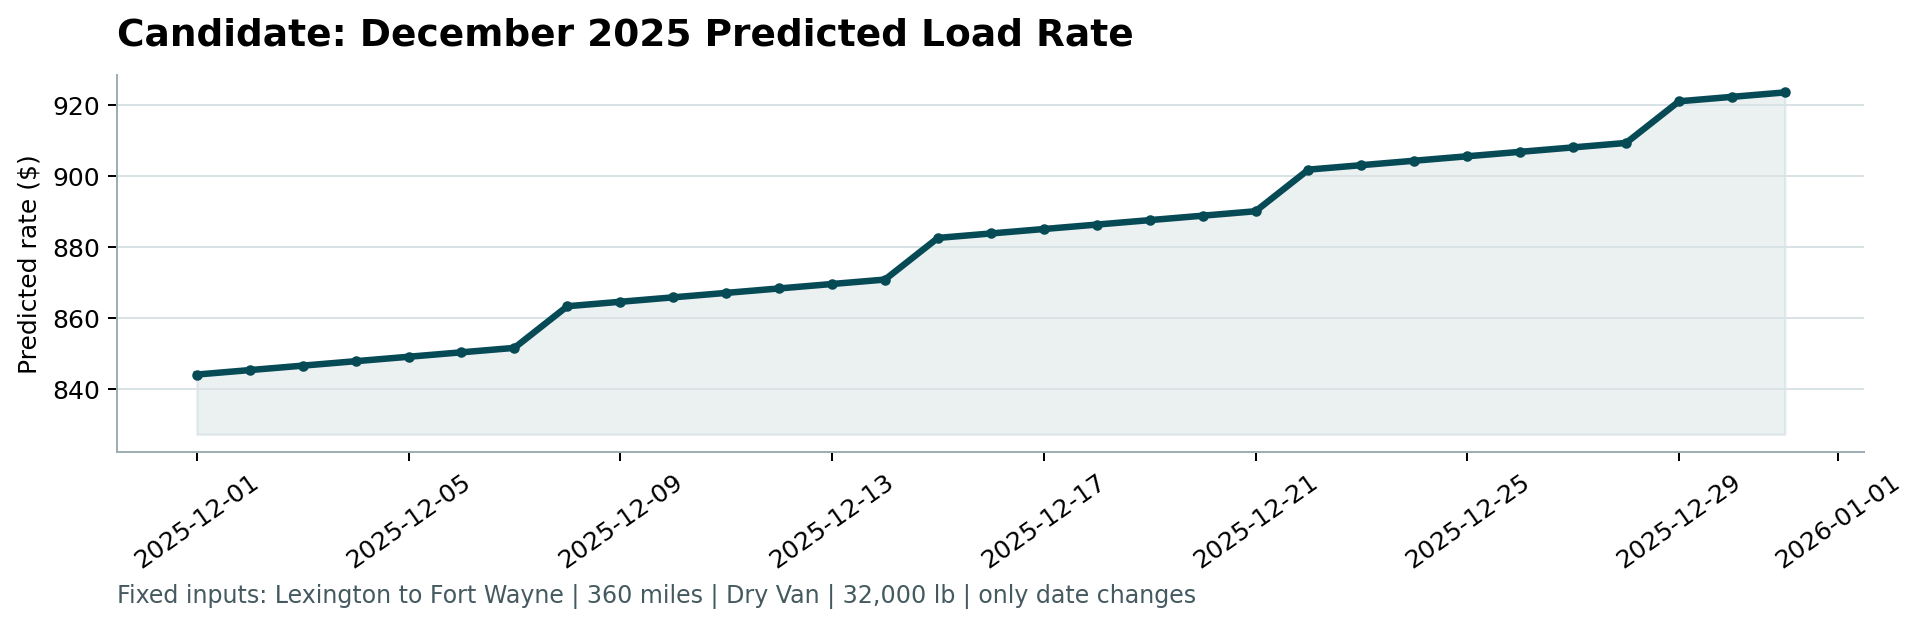

In [83]:
from IPython.display import Image, display

display(Image(
    filename="scorer_results/candidate_december.png"
))